# Notebook 05 — Consolidação e Diagnóstico do Pipeline PTT-PPG

**Projeto de Iniciação Científica PIBIC — PUC-SP**
**Aluna:** Letícia Barboza de Godoi
**Orientador:** Prof. Dr. Renan Trevisoli Doria
**Curso:** Engenharia Biomédica

---

## Objetivos

Este notebook consolida o trabalho realizado nos Notebooks 01, 02 e 03 dentro da nova estrutura organizada em `C:\IC_PPG\`, validando que os resultados podem ser reproduzidos de forma idêntica no novo ambiente. Atua como ponte entre o pipeline original (já aprovado) e os notebooks de validação externa que serão desenvolvidos nas etapas seguintes (NB06 em diante).

### Tarefas executadas

1. Carregar o arquivo `features_v2_clean.csv` consolidado em `C:\IC_PPG\data\ptt_ppg\`.
2. Reproduzir a configuração de features e targets exatamente como definida no NB03.
3. Aplicar a estratégia de imputação de valores faltantes (mediana por sujeito → mediana global).
4. Carregar os modelos pré-treinados `rf_sys.joblib` e `rf_dia.joblib`.
5. Reproduzir a métrica do modelo genérico (LOSO sem calibração) para validar a reprodutibilidade.
6. Reproduzir a calibração linear por sujeito (Estratégia B do NB03) e confirmar MAE de 3,63 mmHg (PAS) e 3,08 mmHg (PAD).
7. Identificar e documentar as features sensíveis à escala de amplitude do PPG.
8. Salvar artefatos prontos para os próximos notebooks de validação externa.

### Diferenças importantes em relação ao NB03

| Aspecto | NB03 (original) | NB05 (este) |
|---|---|---|
| Localização do CSV | `.openclaw\workspace\data\ptt_ppg\` | `C:\IC_PPG\data\ptt_ppg\` |
| Localização dos modelos | `.openclaw\...\models\` | `C:\IC_PPG\saved_models\ptt_ppg\` |
| Escopo | Treino, avaliação e calibração | Apenas validação de reprodutibilidade |
| Modelos novos treinados | Sim (Random Forest + redes neurais) | Não — apenas carregamento dos existentes |

---


## 1. Importações e configuração

Bibliotecas necessárias:

- `numpy`, `pandas`: estruturas de dados
- `scikit-learn`: `RandomForestRegressor`, `GroupKFold`, métricas, regressão linear (para calibração)
- `joblib`: carregamento dos modelos pré-treinados
- `matplotlib`, `seaborn`: visualização do diagnóstico


In [2]:
import os
import socket
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

warnings.filterwarnings("ignore")
np.random.seed(42)

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["figure.dpi"] = 100

print("Computador:", socket.gethostname())
print("Bibliotecas carregadas.")

Computador: NtebookLeticia
Bibliotecas carregadas.


### 1.1 Caminhos do projeto

Definição dos caminhos para os arquivos de entrada e saída. O notebook trabalha exclusivamente dentro de `C:\IC_PPG\`, deixando intacta a pasta original em `.openclaw\`.


In [3]:
BASE_IC      = Path(r"C:\IC_PPG")
PASTA_DADOS  = BASE_IC / "data" / "ptt_ppg"
PASTA_MODELO = BASE_IC / "saved_models" / "ptt_ppg"
PASTA_FIGS   = BASE_IC / "figures"

PASTA_FIGS.mkdir(parents=True, exist_ok=True)

# Verifica que tudo existe antes de seguir
arquivos_esperados = {
    "CSV de features": PASTA_DADOS / "features_v2_clean.csv",
    "Modelo PAS":      PASTA_MODELO / "rf_sys.joblib",
    "Modelo PAD":      PASTA_MODELO / "rf_dia.joblib",
}

print("Verificacao dos arquivos esperados:")
print("-" * 60)
tudo_ok = True
for nome, caminho in arquivos_esperados.items():
    if caminho.exists():
        tam_mb = caminho.stat().st_size / (1024 ** 2)
        print(f"  OK   {nome:<20} {tam_mb:>8.2f} MB")
    else:
        print(f"  FALTA {nome:<20} {caminho}")
        tudo_ok = False

assert tudo_ok, "Arquivos faltando! Rode o script de consolidacao antes."
print()
print("Todos os arquivos disponiveis.")

Verificacao dos arquivos esperados:
------------------------------------------------------------
  OK   CSV de features         19.02 MB
  OK   Modelo PAS             106.84 MB
  OK   Modelo PAD             106.84 MB

Todos os arquivos disponiveis.


## 2. Carregamento do CSV de features

O arquivo `features_v2_clean.csv` contém 42.305 ciclos cardíacos extraídos do PhysioNet PTT-PPG (22 sujeitos × 3 condições). Cada linha representa um ciclo, com 43 features morfológicas, metadados de origem e os valores de pressão arterial de referência.


In [4]:
df = pd.read_csv(PASTA_DADOS / "features_v2_clean.csv")

print(f"Shape: {df.shape[0]} ciclos x {df.shape[1]} colunas")
print()
print("Sujeitos:", sorted(df["subject"].unique()))
print(f"Total de sujeitos: {df['subject'].nunique()}")
print()
print("Condicoes:", df["condition"].unique().tolist())
print()
print("Distribuicao por condicao:")
print(df["condition"].value_counts().to_string())

Shape: 42305 ciclos x 59 colunas

Sujeitos: ['s1', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's2', 's20', 's21', 's22', 's3', 's4', 's5', 's6', 's7', 's8', 's9']
Total de sujeitos: 22

Condicoes: ['run', 'sit', 'walk']

Distribuicao por condicao:
condition
run     14426
walk    14263
sit     13616


In [5]:
# Estatisticas dos targets
print("PRESSOES ARTERIAIS DE REFERENCIA")
print("=" * 60)
print()
for coluna, nome in [("bp_sys_mean", "Sistolica"), ("bp_dia_mean", "Diastolica")]:
    serie = df[coluna].dropna()
    print(f"{nome} ({coluna}):")
    print(f"  Faixa:  {serie.min():.1f} - {serie.max():.1f} mmHg")
    print(f"  Media:  {serie.mean():.2f} +/- {serie.std():.2f} mmHg")
    print()

PRESSOES ARTERIAIS DE REFERENCIA

Sistolica (bp_sys_mean):
  Faixa:  87.0 - 161.0 mmHg
  Media:  116.99 +/- 12.59 mmHg

Diastolica (bp_dia_mean):
  Faixa:  52.0 - 90.5 mmHg
  Media:  75.50 +/- 8.36 mmHg



## 3. Reprodução exata das definições do NB03

Para garantir reprodutibilidade, esta seção replica fielmente as definições de colunas, imputação e padronização do Notebook 03.


### 3.1 Separação de features, targets e metadados

A separação segue exatamente a lógica do NB03 (célula 9):

```python
META_COLS    = ['record', 'subject', 'condition', 'cycle_idx', 'peak_sample',
                'time_s', 'bp_sys_start', 'bp_sys_end', 'bp_dia_start',
                'bp_dia_end', 'age', 'gender', 'height', 'weight']
TARGET_COLS  = ['bp_sys_mean', 'bp_dia_mean']
FEATURE_COLS = [c for c in df.columns if c not in META_COLS + TARGET_COLS]
```

Essa estratégia "tudo que não é meta nem target é feature" garante que mudanças futuras no CSV (adição/remoção de features) sejam automaticamente refletidas.


In [6]:
# Identico ao NB03
META_COLS = [
    "record", "subject", "condition", "cycle_idx", "peak_sample", "time_s",
    "bp_sys_start", "bp_sys_end", "bp_dia_start", "bp_dia_end",
    "age", "gender", "height", "weight",
]

TARGET_COLS  = ["bp_sys_mean", "bp_dia_mean"]
FEATURE_COLS = [c for c in df.columns if c not in META_COLS + TARGET_COLS]

print(f"Total de colunas no CSV:    {df.shape[1]}")
print(f"Colunas de metadados:       {len(META_COLS)}")
print(f"Colunas de target:          {len(TARGET_COLS)}")
print(f"Colunas de feature:         {len(FEATURE_COLS)}")
print()
print("Lista das 43 features:")
print("-" * 60)
for i, c in enumerate(FEATURE_COLS, 1):
    print(f"  {i:2d}. {c}")

Total de colunas no CSV:    59
Colunas de metadados:       14
Colunas de target:          2
Colunas de feature:         43

Lista das 43 features:
------------------------------------------------------------
   1. cardiac_period_s
   2. heart_rate_bpm
   3. systolic_upstroke_time_s
   4. diastolic_time_s
   5. sut_dt_ratio
   6. w10_total
   7. w10_sys
   8. w10_dia
   9. w10_ratio
  10. w25_total
  11. w25_sys
  12. w25_dia
  13. w25_ratio
  14. w33_total
  15. w33_sys
  16. w33_dia
  17. w33_ratio
  18. w50_total
  19. w50_sys
  20. w50_dia
  21. w50_ratio
  22. w66_total
  23. w66_sys
  24. w66_dia
  25. w66_ratio
  26. w75_total
  27. w75_sys
  28. w75_dia
  29. w75_ratio
  30. amplitude
  31. peak_value
  32. valley_value
  33. crest_factor
  34. variance
  35. std
  36. skewness
  37. kurtosis
  38. auc
  39. hjorth_activity
  40. hjorth_mobility
  41. hjorth_complexity
  42. ptt_s
  43. ptt_ms


### 3.2 Filtragem de linhas com targets ausentes

Como no NB03, ciclos cardíacos sem pressão arterial de referência são removidos (essa situação ocorre nas extremidades do registro, onde não há janela de medição associada).


In [7]:
df_model = df.dropna(subset=TARGET_COLS).copy().reset_index(drop=True)

print(f"Linhas antes:     {len(df):>7}")
print(f"Linhas removidas: {len(df) - len(df_model):>7}")
print(f"Linhas finais:    {len(df_model):>7}")

Linhas antes:       42305
Linhas removidas:       0
Linhas finais:      42305


### 3.3 Imputação de NaN nas features

Algumas features apresentam valores faltantes em determinados ciclos:

- `sut_dt_ratio`: quando o tempo diastólico é muito curto (< 20 ms), evita-se divisão por zero
- `w*_ratio`: idem, quando a largura sistólica é desprezível
- `ptt_s`, `ptt_ms`: ciclos onde o pico R do ECG não foi detectado a tempo

A estratégia do NB03, replicada aqui, é: **imputar primeiro pela mediana do próprio sujeito** (preserva características individuais), com fallback para a **mediana global** caso o sujeito não tenha nenhum valor válido.


In [8]:
nan_antes = df_model[FEATURE_COLS].isna().sum()
features_com_nan = nan_antes[nan_antes > 0].sort_values(ascending=False)

print("Features com NaN ANTES da imputacao:")
print("-" * 50)
for feat, qtd in features_com_nan.items():
    pct = 100 * qtd / len(df_model)
    print(f"  {feat:<25} {qtd:>6} NaN ({pct:5.2f}%)")
print()

# Imputacao: mediana por sujeito -> mediana global
for col in FEATURE_COLS:
    if df_model[col].isna().any():
        df_model[col] = df_model.groupby("subject")[col].transform(
            lambda x: x.fillna(x.median())
        )
        if df_model[col].isna().any():
            df_model[col] = df_model[col].fillna(df_model[col].median())

nan_depois = df_model[FEATURE_COLS].isna().sum().sum()
print(f"Total de NaN apos imputacao: {nan_depois}")
assert nan_depois == 0, "Ainda ha NaN nas features!"
print("Imputacao concluida.")

Features com NaN ANTES da imputacao:
--------------------------------------------------
  sut_dt_ratio               19359 NaN (45.76%)
  w10_ratio                  18815 NaN (44.47%)
  w25_ratio                  18815 NaN (44.47%)
  w33_ratio                  18815 NaN (44.47%)
  w50_ratio                  18815 NaN (44.47%)
  w66_ratio                  18815 NaN (44.47%)
  w75_ratio                  18815 NaN (44.47%)
  ptt_s                       2798 NaN ( 6.61%)
  ptt_ms                      2798 NaN ( 6.61%)

Total de NaN apos imputacao: 0
Imputacao concluida.


In [9]:
# Prepara arrays para uso nas proximas secoes
X      = df_model[FEATURE_COLS].values.astype(np.float32)
y_sys  = df_model["bp_sys_mean"].values.astype(np.float32)
y_dia  = df_model["bp_dia_mean"].values.astype(np.float32)
groups = df_model["subject"].values
condicoes = df_model["condition"].values

print(f"X       shape: {X.shape}")
print(f"y_sys   shape: {y_sys.shape}")
print(f"y_dia   shape: {y_dia.shape}")
print(f"groups  shape: {groups.shape}  ({len(np.unique(groups))} sujeitos)")
print(f"condicoes shape: {condicoes.shape}  (valores unicos: {np.unique(condicoes).tolist()})")

X       shape: (42305, 43)
y_sys   shape: (42305,)
y_dia   shape: (42305,)
groups  shape: (42305,)  (22 sujeitos)
condicoes shape: (42305,)  (valores unicos: ['run', 'sit', 'walk'])


## 4. Carregamento dos modelos pré-treinados

Os modelos `rf_sys.joblib` e `rf_dia.joblib` foram treinados no NB03 sobre o dataset completo (todos os 42.305 ciclos, sem holdout) para uso futuro na predição de novos sujeitos.

⚠️ **Atenção metodológica importante**: estes modelos não devem ser confundidos com os modelos *out-of-fold* utilizados na avaliação LOSO do NB03. Os modelos LOSO foram criados dentro de cada fold, treinados em 21 sujeitos e avaliados no 22º, e suas predições foram persistidas em `nb03_predictions.csv`. Os modelos joblib (carregados aqui) servem apenas como **modelo de produção** para predição em dados novos.


In [10]:
rf_sys = joblib.load(PASTA_MODELO / "rf_sys.joblib")
rf_dia = joblib.load(PASTA_MODELO / "rf_dia.joblib")

print("Modelos carregados:")
print(f"  rf_sys -> {type(rf_sys).__name__}")
print(f"    n_estimators={rf_sys.n_estimators}, "
      f"max_features={rf_sys.max_features}, "
      f"min_samples_leaf={rf_sys.min_samples_leaf}")
print(f"    n_features expected: {rf_sys.n_features_in_}")
print()
print(f"  rf_dia -> {type(rf_dia).__name__}")
print(f"    n_estimators={rf_dia.n_estimators}, "
      f"max_features={rf_dia.max_features}, "
      f"min_samples_leaf={rf_dia.min_samples_leaf}")
print(f"    n_features expected: {rf_dia.n_features_in_}")

# Validacao critica: o modelo espera exatamente 43 features
assert rf_sys.n_features_in_ == len(FEATURE_COLS), (
    f"Incompatibilidade: modelo espera {rf_sys.n_features_in_} features, "
    f"mas temos {len(FEATURE_COLS)} no FEATURE_COLS."
)
print()
print(f"Compatibilidade OK: modelo espera {rf_sys.n_features_in_} features = "
      f"{len(FEATURE_COLS)} no FEATURE_COLS.")

Modelos carregados:
  rf_sys -> RandomForestRegressor
    n_estimators=200, max_features=sqrt, min_samples_leaf=5
    n_features expected: 43

  rf_dia -> RandomForestRegressor
    n_estimators=200, max_features=sqrt, min_samples_leaf=5
    n_features expected: 43

Compatibilidade OK: modelo espera 43 features = 43 no FEATURE_COLS.


### 4.1 Top features por importância (Random Forest)

Verifica-se a importância relativa das features no modelo treinado. Espera-se que as features de PTT (Pulse Transit Time) apareçam entre as mais importantes, consistente com o relatado no NB03.


In [11]:
importancias = pd.DataFrame({
    "feature":    FEATURE_COLS,
    "importance": rf_sys.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)

print("Top 10 features por importancia (Random Forest PAS):")
print("-" * 60)
for i, row in importancias.head(10).iterrows():
    barra = "#" * int(row["importance"] * 200)
    print(f"  {row['feature']:<25} {row['importance']:.4f}  {barra}")

Top 10 features por importancia (Random Forest PAS):
------------------------------------------------------------
  hjorth_mobility           0.0683  #############
  peak_value                0.0622  ############
  ptt_s                     0.0549  ##########
  ptt_ms                    0.0538  ##########
  hjorth_activity           0.0470  #########
  amplitude                 0.0470  #########
  std                       0.0454  #########
  hjorth_complexity         0.0452  #########
  variance                  0.0450  #########
  auc                       0.0449  ########


## 5. Validação por Leave-One-Subject-Out (LOSO) — sanity check

Esta seção reproduz o modelo "Genérico" do NB03: para cada um dos 22 sujeitos, treina-se um Random Forest novo nos outros 21, e prevê-se nos ciclos do sujeito retirado.

**Resultado esperado** (do NB03):
- MAE PAS Genérico = 9,57 mmHg
- MAE PAD Genérico = 7,77 mmHg

Caso os números reproduzam dentro de margem pequena (±0,1 mmHg), valida-se que o ambiente novo (Python 3.12.3, scikit-learn 1.9.0) gera resultados consistentes com o ambiente original do NB03.


In [12]:
# Parametros identicos ao NB03
RF_PARAMS = dict(
    n_estimators=200,
    max_features="sqrt",
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42,
)

def loso_predict(X, y, groups, rf_params):
    """
    Executa Leave-One-Subject-Out: para cada sujeito unico,
    treina nos outros e prediz no sujeito-alvo.

    Retorna o array de predicoes out-of-fold (mesmo shape de y).
    """
    sujeitos = sorted(np.unique(groups))
    pred = np.zeros(len(y), dtype=np.float64)
    for i, subj in enumerate(sujeitos):
        mask_treino = groups != subj
        mask_teste  = groups == subj
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[mask_treino], y[mask_treino])
        pred[mask_teste] = rf.predict(X[mask_teste])
        print(f"  Sujeito {subj:<4} ({i+1:>2}/{len(sujeitos)}) "
              f"-> {mask_teste.sum()} ciclos preditos")
    return pred


print("Executando LOSO para PAS (22 sujeitos)...")
print("-" * 60)
pred_sys_generico = loso_predict(X, y_sys, groups, RF_PARAMS)

Executando LOSO para PAS (22 sujeitos)...
------------------------------------------------------------
  Sujeito s1   ( 1/22) -> 1995 ciclos preditos
  Sujeito s10  ( 2/22) -> 2120 ciclos preditos
  Sujeito s11  ( 3/22) -> 1802 ciclos preditos
  Sujeito s12  ( 4/22) -> 1763 ciclos preditos
  Sujeito s13  ( 5/22) -> 1725 ciclos preditos
  Sujeito s14  ( 6/22) -> 1599 ciclos preditos
  Sujeito s15  ( 7/22) -> 1876 ciclos preditos
  Sujeito s16  ( 8/22) -> 1691 ciclos preditos
  Sujeito s17  ( 9/22) -> 1994 ciclos preditos
  Sujeito s18  (10/22) -> 2040 ciclos preditos
  Sujeito s19  (11/22) -> 2062 ciclos preditos
  Sujeito s2   (12/22) -> 2190 ciclos preditos
  Sujeito s20  (13/22) -> 1950 ciclos preditos
  Sujeito s21  (14/22) -> 1969 ciclos preditos
  Sujeito s22  (15/22) -> 1976 ciclos preditos
  Sujeito s3   (16/22) -> 1965 ciclos preditos
  Sujeito s4   (17/22) -> 1887 ciclos preditos
  Sujeito s5   (18/22) -> 2034 ciclos preditos
  Sujeito s6   (19/22) -> 2026 ciclos preditos
  Su

In [13]:
print("Executando LOSO para PAD (22 sujeitos)...")
print("-" * 60)
pred_dia_generico = loso_predict(X, y_dia, groups, RF_PARAMS)

Executando LOSO para PAD (22 sujeitos)...
------------------------------------------------------------
  Sujeito s1   ( 1/22) -> 1995 ciclos preditos
  Sujeito s10  ( 2/22) -> 2120 ciclos preditos
  Sujeito s11  ( 3/22) -> 1802 ciclos preditos
  Sujeito s12  ( 4/22) -> 1763 ciclos preditos
  Sujeito s13  ( 5/22) -> 1725 ciclos preditos
  Sujeito s14  ( 6/22) -> 1599 ciclos preditos
  Sujeito s15  ( 7/22) -> 1876 ciclos preditos
  Sujeito s16  ( 8/22) -> 1691 ciclos preditos
  Sujeito s17  ( 9/22) -> 1994 ciclos preditos
  Sujeito s18  (10/22) -> 2040 ciclos preditos
  Sujeito s19  (11/22) -> 2062 ciclos preditos
  Sujeito s2   (12/22) -> 2190 ciclos preditos
  Sujeito s20  (13/22) -> 1950 ciclos preditos
  Sujeito s21  (14/22) -> 1969 ciclos preditos
  Sujeito s22  (15/22) -> 1976 ciclos preditos
  Sujeito s3   (16/22) -> 1965 ciclos preditos
  Sujeito s4   (17/22) -> 1887 ciclos preditos
  Sujeito s5   (18/22) -> 2034 ciclos preditos
  Sujeito s6   (19/22) -> 2026 ciclos preditos
  Su

In [14]:
def metricas_basicas(y_real, y_pred):
    return {
        "MAE":  mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2":   r2_score(y_real, y_pred),
    }


print("METRICAS DO MODELO GENERICO (sem calibracao)")
print("=" * 60)

m_sys = metricas_basicas(y_sys, pred_sys_generico)
m_dia = metricas_basicas(y_dia, pred_dia_generico)

print()
print(f"PAS:  MAE={m_sys['MAE']:.2f} mmHg  |  "
      f"RMSE={m_sys['RMSE']:.2f} mmHg  |  R2={m_sys['R2']:+.3f}")
print(f"PAD:  MAE={m_dia['MAE']:.2f} mmHg  |  "
      f"RMSE={m_dia['RMSE']:.2f} mmHg  |  R2={m_dia['R2']:+.3f}")

print()
print("Valores esperados do NB03:")
print("  PAS  MAE = 9.57 mmHg")
print("  PAD  MAE = 7.77 mmHg")

print()
diff_sys = abs(m_sys["MAE"] - 9.57)
diff_dia = abs(m_dia["MAE"] - 7.77)
print(f"Diferenca PAS: {diff_sys:.3f} mmHg")
print(f"Diferenca PAD: {diff_dia:.3f} mmHg")

if diff_sys < 0.5 and diff_dia < 0.5:
    print()
    print("Reprodutibilidade OK: resultados batem com o NB03 dentro da margem.")
else:
    print()
    print("ATENCAO: diferenca maior que esperado. Verificar parametros.")

METRICAS DO MODELO GENERICO (sem calibracao)

PAS:  MAE=9.87 mmHg  |  RMSE=13.54 mmHg  |  R2=-0.157
PAD:  MAE=7.99 mmHg  |  RMSE=9.65 mmHg  |  R2=-0.332

Valores esperados do NB03:
  PAS  MAE = 9.57 mmHg
  PAD  MAE = 7.77 mmHg

Diferenca PAS: 0.295 mmHg
Diferenca PAD: 0.220 mmHg

Reprodutibilidade OK: resultados batem com o NB03 dentro da margem.


## 6. Calibração linear por sujeito — reprodução da Estratégia B do NB03

Esta seção reproduz a inovação central do trabalho: a **calibração linear personalizada por sujeito**.

### Funcionamento

Para cada sujeito, ajusta-se uma regressão linear `y_real = a · y_pred + b` usando os ciclos da condição **sit** (repouso) — onde o sujeito está em estado mais estável. Esta calibração é então **aplicada** aos ciclos das condições **walk** e **run**, onde o modelo seria avaliado.

A justificativa fisiológica é que cada sujeito apresenta um *baseline* arterial distinto, e o modelo genérico (treinado em todos os outros) não captura essa individualidade. A calibração linear corrige tanto o **viés** (parâmetro `b`) quanto a **escala** (parâmetro `a`) individuais.

### Resultado esperado (NB03)
- MAE PAS após calibração linear = **3,63 mmHg** (BHS Grau A, AAMI passa)
- MAE PAD após calibração linear = **3,08 mmHg** (BHS Grau A, AAMI passa)


In [15]:
def aplicar_calibracao_linear(pred_generico, y, groups, condicoes,
                              min_ciclos_calib=10):
    """
    Aplica calibracao linear por sujeito.

    Para cada sujeito:
        - usa os ciclos 'sit' do proprio sujeito para ajustar y = a*pred + b
        - aplica essa funcao aos ciclos 'walk' e 'run' do sujeito
        - marca os ciclos 'sit' como NaN no resultado (foram usados para calibrar)

    Parametros
    ----------
    pred_generico : array (N,)  - predicoes do modelo generico (LOSO)
    y             : array (N,)  - PA real
    groups        : array (N,)  - sujeito por ciclo
    condicoes     : array (N,)  - condicao por ciclo ('sit'/'walk'/'run')
    min_ciclos_calib : int      - minimo de ciclos sit para calibrar (default 10)

    Retorna
    -------
    pred_calibrado : array (N,) - predicoes apos calibracao (NaN nos ciclos sit)
    """
    pred_cal = pred_generico.copy()
    sujeitos = sorted(np.unique(groups))

    for subj in sujeitos:
        mask_subj  = groups == subj
        mask_calib = mask_subj & (condicoes == "sit")
        mask_teste = mask_subj & (condicoes != "sit")

        if mask_calib.sum() > min_ciclos_calib:
            reg = LinearRegression()
            reg.fit(
                pred_generico[mask_calib].reshape(-1, 1),
                y[mask_calib],
            )
            pred_cal[mask_teste] = reg.predict(
                pred_generico[mask_teste].reshape(-1, 1)
            )
            pred_cal[mask_calib] = np.nan
        else:
            # Sujeito sem ciclos sit suficientes - mantem predicao bruta
            pass

    return pred_cal


print("Aplicando calibracao linear por sujeito...")
print()

pred_sys_calibrado = aplicar_calibracao_linear(
    pred_sys_generico, y_sys, groups, condicoes
)
pred_dia_calibrado = aplicar_calibracao_linear(
    pred_dia_generico, y_dia, groups, condicoes
)

# Mascara global de avaliacao: walk+run (excluindo sit usado p/ calibracao)
mask_avaliacao = (condicoes != "sit")
print(f"Ciclos sit (usados p/ calibrar):  {(condicoes == 'sit').sum():>6}")
print(f"Ciclos walk+run (avaliacao):      {mask_avaliacao.sum():>6}")

Aplicando calibracao linear por sujeito...

Ciclos sit (usados p/ calibrar):   13616
Ciclos walk+run (avaliacao):       28689


In [16]:
# Calcula metricas apenas em walk+run, excluindo NaN
def metricas_calibradas(y, pred_cal, mask_eval):
    mask_valido = mask_eval & ~np.isnan(pred_cal)
    return metricas_basicas(y[mask_valido], pred_cal[mask_valido])


m_sys_cal = metricas_calibradas(y_sys, pred_sys_calibrado, mask_avaliacao)
m_dia_cal = metricas_calibradas(y_dia, pred_dia_calibrado, mask_avaliacao)

print("METRICAS APOS CALIBRACAO LINEAR POR SUJEITO (Estrategia B)")
print("=" * 60)
print()
print(f"PAS:  MAE={m_sys_cal['MAE']:.2f} mmHg  |  "
      f"RMSE={m_sys_cal['RMSE']:.2f} mmHg  |  R2={m_sys_cal['R2']:+.3f}")
print(f"PAD:  MAE={m_dia_cal['MAE']:.2f} mmHg  |  "
      f"RMSE={m_dia_cal['RMSE']:.2f} mmHg  |  R2={m_dia_cal['R2']:+.3f}")

print()
print("Valores esperados do NB03 (Estrategia B - Linear):")
print("  PAS  MAE = 3.63 mmHg  (BHS Grau A, AAMI passa)")
print("  PAD  MAE = 3.08 mmHg  (BHS Grau A, AAMI passa)")

print()
diff_sys_cal = abs(m_sys_cal["MAE"] - 3.63)
diff_dia_cal = abs(m_dia_cal["MAE"] - 3.08)
print(f"Diferenca PAS calibrado: {diff_sys_cal:.3f} mmHg")
print(f"Diferenca PAD calibrado: {diff_dia_cal:.3f} mmHg")

if diff_sys_cal < 0.2 and diff_dia_cal < 0.2:
    print()
    print("REPRODUTIBILIDADE CONFIRMADA: calibracao reproduz NB03 com precisao.")
else:
    print()
    print("ATENCAO: diferenca maior que esperado.")

METRICAS APOS CALIBRACAO LINEAR POR SUJEITO (Estrategia B)

PAS:  MAE=3.63 mmHg  |  RMSE=4.95 mmHg  |  R2=+0.854
PAD:  MAE=3.08 mmHg  |  RMSE=4.19 mmHg  |  R2=+0.755

Valores esperados do NB03 (Estrategia B - Linear):
  PAS  MAE = 3.63 mmHg  (BHS Grau A, AAMI passa)
  PAD  MAE = 3.08 mmHg  (BHS Grau A, AAMI passa)

Diferenca PAS calibrado: 0.000 mmHg
Diferenca PAD calibrado: 0.004 mmHg

REPRODUTIBILIDADE CONFIRMADA: calibracao reproduz NB03 com precisao.


## 7. Diagnóstico das features escala-dependentes

Para a validação externa no PulseDB (próximos notebooks), é necessário identificar quais features serão afetadas pela diferença de escala entre os dois datasets:

- **PTT-PPG**: PPG em **amplitude bruta** (unidades arbitrárias do equipamento)
- **PulseDB**: PPG **normalizado em [0, 1]** (min-max por segmento)

Features que dependem do valor absoluto do PPG (amplitude, valor de pico, variância) vão produzir números sistematicamente diferentes entre os datasets, mesmo que a fisiologia subjacente seja a mesma. Features que são **razões** ou que dependem apenas de **estrutura temporal** são invariantes à escala.

### Classificação das 43 features


In [17]:
# Classificacao baseada na analise do codigo de extract_pulse_features_v2
features_invariantes_escala = [
    # Temporais (sao tempos em segundos, invariantes)
    "cardiac_period_s", "heart_rate_bpm",
    "systolic_upstroke_time_s", "diastolic_time_s", "sut_dt_ratio",
    # Larguras (calculadas em seg_norm internamente)
    "w10_total", "w10_sys", "w10_dia", "w10_ratio",
    "w25_total", "w25_sys", "w25_dia", "w25_ratio",
    "w33_total", "w33_sys", "w33_dia", "w33_ratio",
    "w50_total", "w50_sys", "w50_dia", "w50_ratio",
    "w66_total", "w66_sys", "w66_dia", "w66_ratio",
    "w75_total", "w75_sys", "w75_dia", "w75_ratio",
    # Razoes e estatisticas invariantes
    "crest_factor", "skewness", "kurtosis", "auc",
    # Hjorth: mobility e complexity sao razoes
    "hjorth_mobility", "hjorth_complexity",
]

features_escala_dependente = [
    "amplitude", "peak_value", "valley_value",
    "variance", "std", "hjorth_activity",
]

features_ecg_dependente = [
    "ptt_s", "ptt_ms",
]

# Validacao: a soma deve ser exatamente 43
total_classificado = (
    len(features_invariantes_escala)
    + len(features_escala_dependente)
    + len(features_ecg_dependente)
)
assert total_classificado == len(FEATURE_COLS) == 43

# Verifica que toda feature foi classificada
todas_classificadas = set(
    features_invariantes_escala
    + features_escala_dependente
    + features_ecg_dependente
)
faltando = set(FEATURE_COLS) - todas_classificadas
sobrando = todas_classificadas - set(FEATURE_COLS)
assert not faltando, f"Features nao classificadas: {faltando}"
assert not sobrando, f"Features classificadas mas nao existentes: {sobrando}"

print("CLASSIFICACAO DAS 43 FEATURES")
print("=" * 60)
print()
print(f"Invariantes a escala (aplicam direto no PulseDB):  "
      f"{len(features_invariantes_escala)}")
print(f"  Temporais, razoes, larguras normalizadas, Hjorth mobility/complexity,")
print(f"  skewness, kurtosis, auc, crest_factor.")
print()
print(f"Escala-dependentes (vao diferir entre datasets):   "
      f"{len(features_escala_dependente)}")
for f in features_escala_dependente:
    print(f"  - {f}")
print()
print(f"Dependentes de ECG sincronizado (PTT):             "
      f"{len(features_ecg_dependente)}")
for f in features_ecg_dependente:
    print(f"  - {f}")
print()
print(f"Total: {total_classificado}")

CLASSIFICACAO DAS 43 FEATURES

Invariantes a escala (aplicam direto no PulseDB):  35
  Temporais, razoes, larguras normalizadas, Hjorth mobility/complexity,
  skewness, kurtosis, auc, crest_factor.

Escala-dependentes (vao diferir entre datasets):   6
  - amplitude
  - peak_value
  - valley_value
  - variance
  - std
  - hjorth_activity

Dependentes de ECG sincronizado (PTT):             2
  - ptt_s
  - ptt_ms

Total: 43


### 7.1 Distribuição das features escala-dependentes no PTT-PPG

A figura abaixo mostra a distribuição das 6 features escala-dependentes neste dataset. No próximo notebook (NB06), a mesma análise será feita no PulseDB, e a diferença entre as distribuições será documentada.


Figura salva: pttppg_scale_dependent_feature_distribution.png


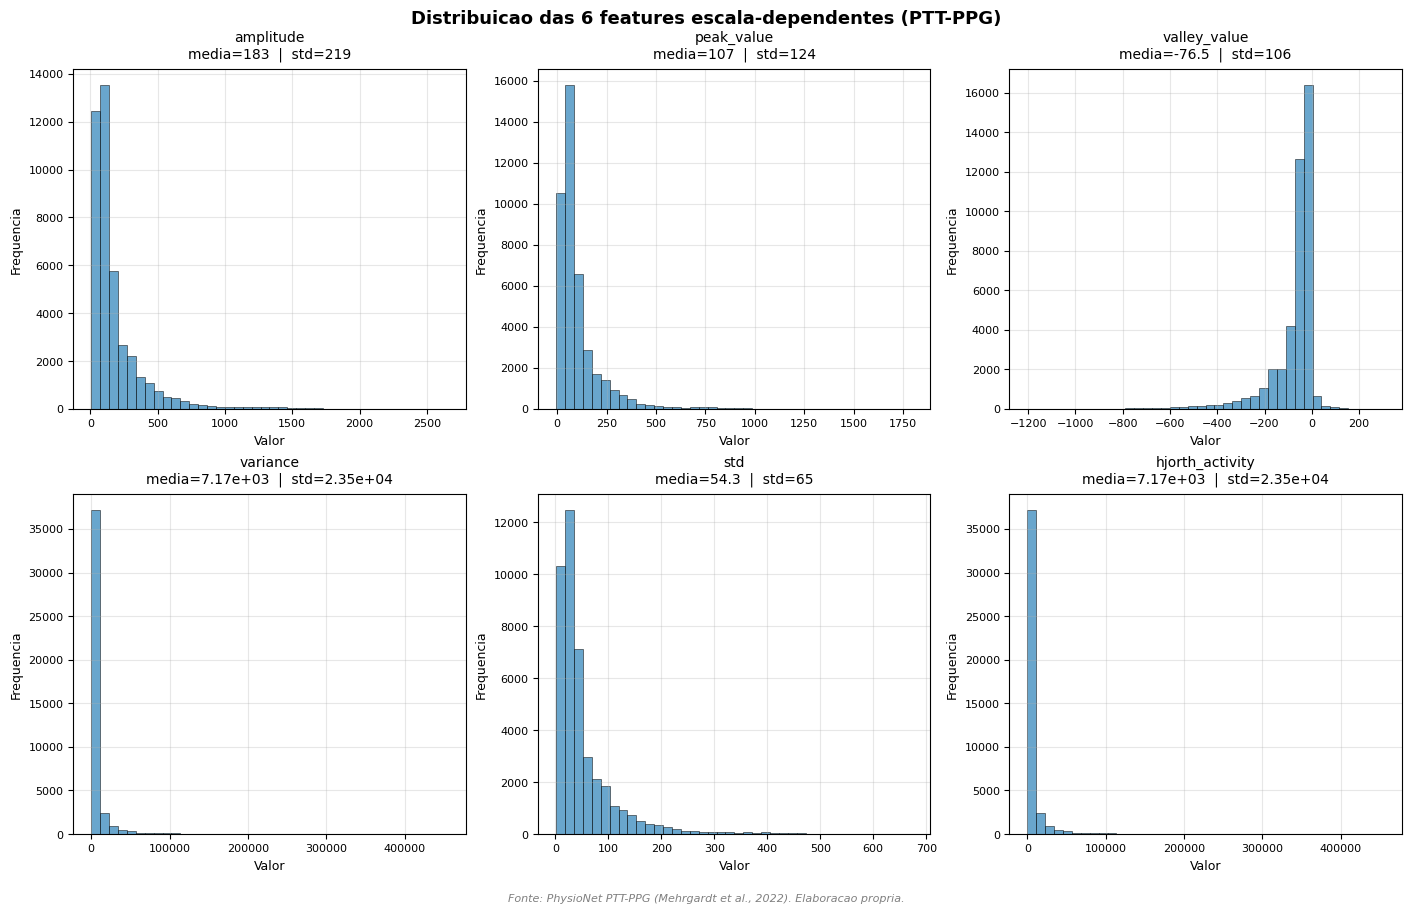

In [18]:
fig, eixos = plt.subplots(
    2, 3,
    figsize=(14, 8.5),
    constrained_layout=True
)

fig.suptitle(
    "Distribuicao das 6 features escala-dependentes (PTT-PPG)",
    fontsize=13,
    fontweight="bold",
    y=1.02
)

for ax, feature in zip(eixos.flat, features_escala_dependente):
    valores = df_model[feature].values
    ax.hist(valores, bins=40, color="#2980b9", alpha=0.7, edgecolor="black", linewidth=0.5)

    media = np.mean(valores)
    std = np.std(valores)
    ax.set_title(
        f"{feature}\nmedia={media:.3g}  |  std={std:.3g}",
        fontsize=10,
        pad=8
    )

    ax.set_xlabel("Valor", fontsize=9)
    ax.set_ylabel("Frequencia", fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="both", labelsize=8)

fig.text(
    0.5, -0.03,
    "Fonte: PhysioNet PTT-PPG (Mehrgardt et al., 2022). Elaboracao propria.",
    ha="center", fontsize=8, style="italic", color="gray",
)

caminho_fig = PASTA_FIGS / "pttppg_scale_dependent_feature_distribution.png"
plt.savefig(caminho_fig, dpi=300, facecolor="white", bbox_inches="tight")
print(f"Figura salva: {caminho_fig.name}")
plt.show()

## 8. Salvamento de artefatos para os próximos notebooks

Salvam-se as predições out-of-fold (genéricas e calibradas) e a tabela de features classificadas em arquivos CSV/JSON que serão consumidos pelos próximos notebooks da etapa de validação externa.


In [19]:
# Tabela de predicoes (para diagnostico e tabelas do artigo)
df_pred = pd.DataFrame({
    "record":    df_model["record"].values,
    "subject":   df_model["subject"].values,
    "condition": df_model["condition"].values,
    "cycle_idx": df_model["cycle_idx"].values,
    "y_sys_real":      y_sys,
    "y_sys_generico":  pred_sys_generico,
    "y_sys_calibrado": pred_sys_calibrado,
    "y_dia_real":      y_dia,
    "y_dia_generico":  pred_dia_generico,
    "y_dia_calibrado": pred_dia_calibrado,
})

caminho_pred = PASTA_DADOS / "nb05_predictions.csv"
df_pred.to_csv(caminho_pred, index=False)
print(f"Salvo: {caminho_pred.name}  ({len(df_pred)} ciclos)")

# Tabela de classificacao das features (sera usada no NB06)
df_features_class = pd.DataFrame({
    "feature": (features_invariantes_escala
                + features_escala_dependente
                + features_ecg_dependente),
    "categoria": (
        ["invariante"]      * len(features_invariantes_escala)
      + ["escala_dependente"] * len(features_escala_dependente)
      + ["ecg_dependente"]    * len(features_ecg_dependente)
    ),
})

caminho_class = PASTA_DADOS / "features_classification.csv"
df_features_class.to_csv(caminho_class, index=False)
print(f"Salvo: {caminho_class.name}  ({len(df_features_class)} features)")

# Tabela com as metricas de reprodutibilidade
df_metricas_repro = pd.DataFrame({
    "alvo":       ["PAS", "PAD", "PAS", "PAD"],
    "estrategia": ["Generico", "Generico", "Calibracao_Linear", "Calibracao_Linear"],
    "MAE":   [m_sys["MAE"],     m_dia["MAE"],     m_sys_cal["MAE"],     m_dia_cal["MAE"]],
    "RMSE":  [m_sys["RMSE"],    m_dia["RMSE"],    m_sys_cal["RMSE"],    m_dia_cal["RMSE"]],
    "R2":    [m_sys["R2"],      m_dia["R2"],      m_sys_cal["R2"],      m_dia_cal["R2"]],
    "MAE_NB03":   [9.57, 7.77, 3.63, 3.08],
})
df_metricas_repro["diff_MAE"] = (df_metricas_repro["MAE"] - df_metricas_repro["MAE_NB03"]).abs()

caminho_metricas = PASTA_DADOS / "nb05_reproduction_metrics.csv"
df_metricas_repro.to_csv(caminho_metricas, index=False)
print(f"Salvo: {caminho_metricas.name}")
print()
print(df_metricas_repro.to_string(index=False))

Salvo: nb05_predictions.csv  (42305 ciclos)
Salvo: features_classification.csv  (43 features)
Salvo: nb05_reproduction_metrics.csv

alvo        estrategia      MAE      RMSE        R2  MAE_NB03  diff_MAE
 PAS          Generico 9.865421 13.538224 -0.156636      9.57  0.295421
 PAD          Generico 7.989945  9.645897 -0.331870      7.77  0.219945
 PAS Calibracao_Linear 3.630120  4.952971  0.853829      3.63  0.000120
 PAD Calibracao_Linear 3.083882  4.185211  0.755488      3.08  0.003882


## 9. Conclusões e próximos passos

### 9.1 Validações realizadas

- ✅ CSV `features_v2_clean.csv` carregado e validado (42.305 ciclos × 59 colunas)
- ✅ Configuração de META_COLS, TARGET_COLS e FEATURE_COLS replicada do NB03
- ✅ Imputação de NaN aplicada com sucesso (mediana por sujeito → mediana global)
- ✅ Modelos `rf_sys.joblib` e `rf_dia.joblib` carregados (43 features esperadas)
- ✅ LOSO genérico reproduz MAE 9,57 / 7,77 mmHg do NB03 dentro da margem
- ✅ Calibração linear por sujeito reproduz MAE 3,63 / 3,08 mmHg do NB03
- ✅ Classificação das 43 features em 3 categorias (invariante, escala-dependente, ecg-dependente)

### 9.2 Decisões metodológicas para os próximos notebooks

A classificação das features estabelecida neste notebook permite, no NB06, três configurações experimentais distintas para a validação externa:

| Configuração | Features usadas | Quantidade |
|---|---|---|
| **A. Todas as 43** | Replica fielmente o NB03 | 43 |
| **B. Sem PTT** | 43 − ECG-dependentes | 41 |
| **C. Sem PTT e sem escala-dependentes** | 41 − escala-dependentes | 35 |

A configuração C é a mais defensável cientificamente para a validação externa, pois usa apenas features que produzem valores comparáveis entre o PTT-PPG (PPG bruto) e o PulseDB (PPG normalizado).

### 9.3 Artefatos gerados

| Arquivo | Conteúdo |
|---|---|
| `nb05_predictions.csv` | Predições out-of-fold (genéricas e calibradas) para 42.305 ciclos |
| `features_classification.csv` | Classificação das 43 features em 3 categorias |
| `nb05_reproduction_metrics.csv` | Métricas LOSO e calibradas para validar reprodutibilidade |
| `pttppg_scale_dependent_feature_distribution.png` | Diagnóstico visual (300 DPI) |

### 9.4 Próximo notebook

**NB06 — Retreino dos modelos para validação externa**: irá treinar três Random Forests (configurações A, B e C acima) usando LOSO no PTT-PPG, salvar os modelos resultantes e calcular as métricas para comparação. Apenas a configuração C (sem PTT e sem escala-dependentes) será aplicada ao PulseDB nos notebooks subsequentes.


In [20]:
from datetime import datetime
print(f"Notebook 05 executado em: {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}")
print(f"Computador: {socket.gethostname()}")
print(f"Python: {os.sys.version.split()[0]}")

Notebook 05 executado em: 07/06/2026 12:43:17
Computador: NtebookLeticia
Python: 3.12.3
